In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from google.colab import files

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
uploaded = files.upload()


import pandas as pd
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# Clean column names
df.columns = df.columns.str.strip()

# Parse dates safely
date_text = df["Date"].astype(str).str.strip()

# Try common date formats
parsed_dates = pd.to_datetime(
    date_text,
    format="%d/%m/%Y",
    errors="coerce"
)

# Try YYYY-MM-DD for dates that did not parse
missing = parsed_dates.isna()
parsed_dates.loc[missing] = pd.to_datetime(
    date_text.loc[missing],
    format="%Y-%m-%d",
    errors="coerce"
)

# Try MM/DD/YYYY for remaining dates, if any
missing = parsed_dates.isna()
parsed_dates.loc[missing] = pd.to_datetime(
    date_text.loc[missing],
    format="%m/%d/%Y",
    errors="coerce"
)

# Stop if any dates remain invalid
if parsed_dates.isna().any():
    print("Unrecognized date values:")
    print(date_text[parsed_dates.isna()].head(20))
    raise ValueError(
        "Some dates could not be parsed. Check the date format."
    )

df["Date"] = parsed_dates

# Convert numerical columns
columns = ["Open", "High", "Low", "Close", "Volume"]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())


Saving random_stock_market_dataset.csv to random_stock_market_dataset (1).csv


Saving random_stock_market_dataset.csv to random_stock_market_dataset (2).csv
Dataset loaded successfully!
Shape: (60, 6)
Date range: 2024-01-01 00:00:00 to 2024-02-29 00:00:00


,Date,Open,High,Low,Close,Volume
0,2024-01-01,296.45,307.31,293.96,303.72,93133
1,2024-01-02,190.11,193.10,187.21,191.40,64993
2,2024-01-03,197.41,208.64,193.37,205.89,70326
3,2024-01-04,253.13,262.67,248.67,258.95,17358
4,2024-01-05,241.35,253.09,238.99,252.20,20847


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df["Date"].duplicated().sum())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

# Remove duplicate dates if any
df = df.drop_duplicates(subset="Date", keep="last")
df = df.sort_values("Date").reset_index(drop=True)

# Remove rows with missing values in required columns
df = df.dropna(subset=["Date"] + columns).reset_index(drop=True)

# Basic OHLC validation
invalid_ohlc = (
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1)) |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1)) |
    (df["Volume"] < 0)
)

print("\nRows with invalid OHLC or negative volume:",
      invalid_ohlc.sum())

if invalid_ohlc.any():
    raise ValueError("Inspect the invalid rows before training.")

print("\nFinal dataset shape:", df.shape)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    60 non-null     datetime64[ns]
 1   Open    60 non-null     float64       
 2   High    60 non-null     float64       
 3   Low     60 non-null     float64       
 4   Close   60 non-null     float64       
 5   Volume  60 non-null     int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 2.9 KB

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate dates: 0

Date range:
2024-01-01 00:00:00 to 2024-02-29 00:00:00

Rows with invalid OHLC or negative volume: 0

Final dataset shape: (60, 6)


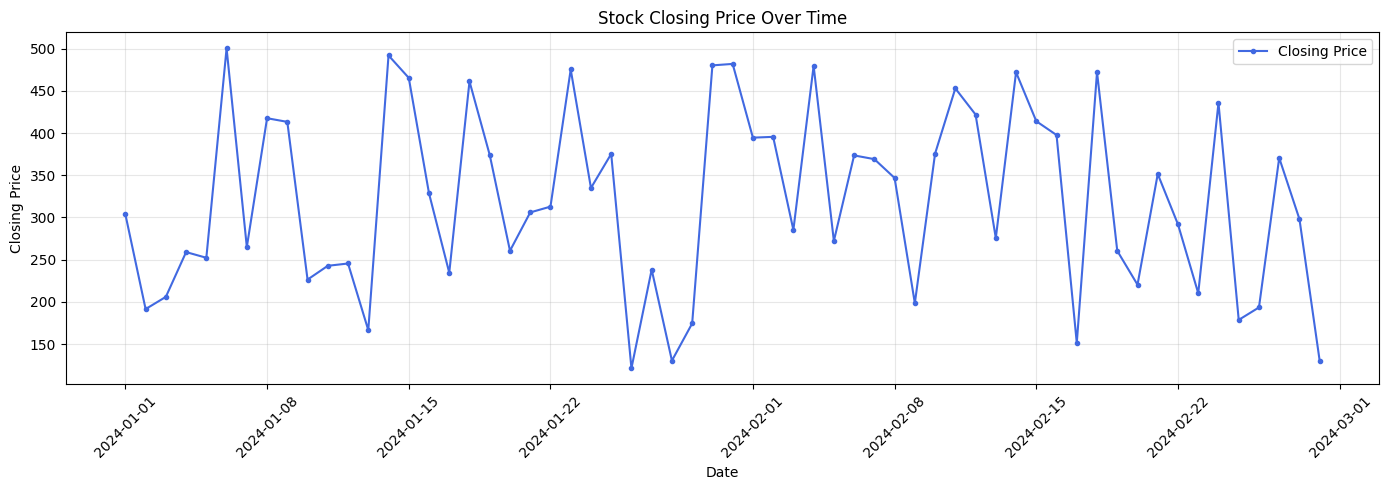

In [5]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Date"],
    df["Close"],
    color="royalblue",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Closing Price"
)

plt.title("Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
FEATURES = ["Open", "High", "Low", "Close", "Volume"]
TARGET = "Close"

LOOKBACK = 10

if len(df) <= LOOKBACK + 5:
    raise ValueError("Not enough rows to create training sequences.")

split_idx = int(len(df) * 0.80)

if split_idx <= LOOKBACK:
    raise ValueError("Training period is too short for this lookback.")

# Chronological split boundary
print("Total rows:", len(df))
print("Training period:", df["Date"].iloc[0], "to",
      df["Date"].iloc[split_idx - 1])
print("Testing period:", df["Date"].iloc[split_idx], "to",
      df["Date"].iloc[-1])

# Separate scalers for inputs and target
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

# Fit scalers using only the training period
feature_scaler.fit(df.loc[:split_idx - 1, FEATURES])
target_scaler.fit(df.loc[:split_idx - 1, [TARGET]])

# Transform the entire series using training-fitted scalers
X_scaled = feature_scaler.transform(df[FEATURES])
y_scaled = target_scaler.transform(df[[TARGET]]).flatten()

print("\nInput features:", FEATURES)
print("Lookback window:", LOOKBACK, "days")

Total rows: 60
Training period: 2024-01-01 00:00:00 to 2024-02-17 00:00:00
Testing period: 2024-02-18 00:00:00 to 2024-02-29 00:00:00

Input features: ['Open', 'High', 'Low', 'Close', 'Volume']
Lookback window: 10 days


In [7]:
X_train, y_train = [], []
X_test, y_test = [], []

test_target_indices = []

for i in range(LOOKBACK, len(df)):
    sequence = X_scaled[i - LOOKBACK:i]
    target = y_scaled[i]

    # Keep the split strictly chronological
    if i < split_idx:
        X_train.append(sequence)
        y_train.append(target)
    else:
        X_test.append(sequence)
        y_test.append(target)
        test_target_indices.append(i)

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

assert len(X_train) > 0 and len(X_test) > 0

X_train shape: (38, 10, 5)
y_train shape: (38,)
X_test shape: (12, 10, 5)
y_test shape: (12,)


In [8]:
model = Sequential([
    Input(shape=(LOOKBACK, len(FEATURES))),

    LSTM(
        units=32,
        activation="tanh",
        recurrent_activation="sigmoid"
    ),

    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,409 (21.13 KB)

 Trainable params: 5,409 (21.13 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 308ms/step - loss: 0.3098 - mae: 0.4774 - val_loss: 0.2560 - val_mae: 0.4584 - learning_rate: 0.0010
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.2031 - mae: 0.3758 - val_loss: 0.1652 - val_mae: 0.3708 - learning_rate: 0.0010
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.1485 - mae: 0.3153 - val_loss: 0.1081 - val_mae: 0.3006 - learning_rate: 0.0010
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 0.0947 - mae: 0.2532 - val_loss: 0.0913 - val_mae: 0.2567 - learning_rate: 0.0010
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - loss: 0.0938 - mae: 0.2498 - val_loss: 0.1015 - val_mae: 0.2309 - learning_rate: 0.0010
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - loss: 0.1121 - mae: 0.2756 - val_loss: 0.1042 - val_mae: 0.2308 - learning_rate: 0.0010
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 171ms/step - loss: 0.1067 - mae: 0.2874 - val_loss: 0.0973 - val_mae: 0.2322 - learning_rate: 0.0010
Epoch 8/100
4/4 

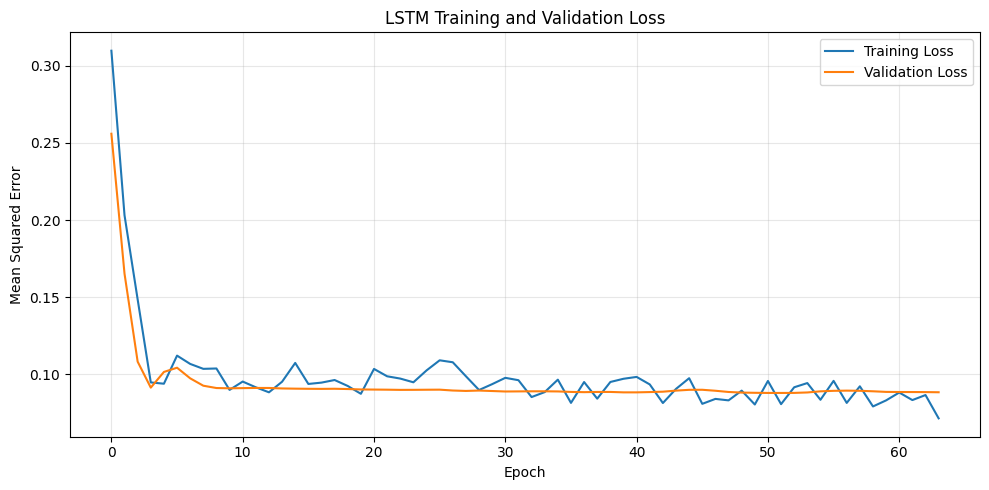

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
y_pred_scaled = model.predict(X_test, verbose=0)

y_pred = target_scaler.inverse_transform(
    y_pred_scaled
).flatten()

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

test_dates = df.iloc[test_target_indices]["Date"].reset_index(drop=True)

results = pd.DataFrame({
    "Date": test_dates,
    "Actual Close": y_actual,
    "Predicted Close": y_pred
})

results["Absolute Error"] = np.abs(
    results["Actual Close"] - results["Predicted Close"]
)

display(results.round(2))

,Date,Actual Close,Predicted Close,Absolute Error
0,2024-02-18,472.230011,333.250000,138.979996
1,2024-02-19,260.410004,358.690002,98.279999
2,2024-02-20,220.309998,342.700012,122.389999
3,2024-02-21,351.459991,336.399994,15.060000
4,2024-02-22,291.790009,344.209991,52.419998
5,2024-02-23,210.199997,338.450012,128.250000
6,2024-02-24,435.790009,327.769989,108.019997
7,2024-02-25,178.580002,348.519989,169.940002
8,2024-02-26,193.360001,325.839996,132.479996
9,2024-02-27,370.559998,316.799988,53.759998


In [12]:
mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

r2 = r2_score(y_actual, y_pred)

# Naive baseline: predict the last observed close
baseline_pred = df.iloc[
    np.array(test_target_indices) - 1
]["Close"].to_numpy()

baseline_mae = mean_absolute_error(
    y_actual, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_actual, baseline_pred)
)

print("LSTM MODEL PERFORMANCE")
print("-" * 35)
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

print("\nNAIVE BASELINE PERFORMANCE")
print("-" * 35)
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")

if mae < baseline_mae:
    print("\nLSTM has lower test MAE than the naive baseline.")
else:
    print("\nLSTM does not outperform the naive baseline on test MAE.")

LSTM MODEL PERFORMANCE
-----------------------------------
MAE:  104.0532
RMSE: 116.7895
R²:   -0.3212

NAIVE BASELINE PERFORMANCE
-----------------------------------
MAE:  146.7175
RMSE: 172.9734

LSTM has lower test MAE than the naive baseline.


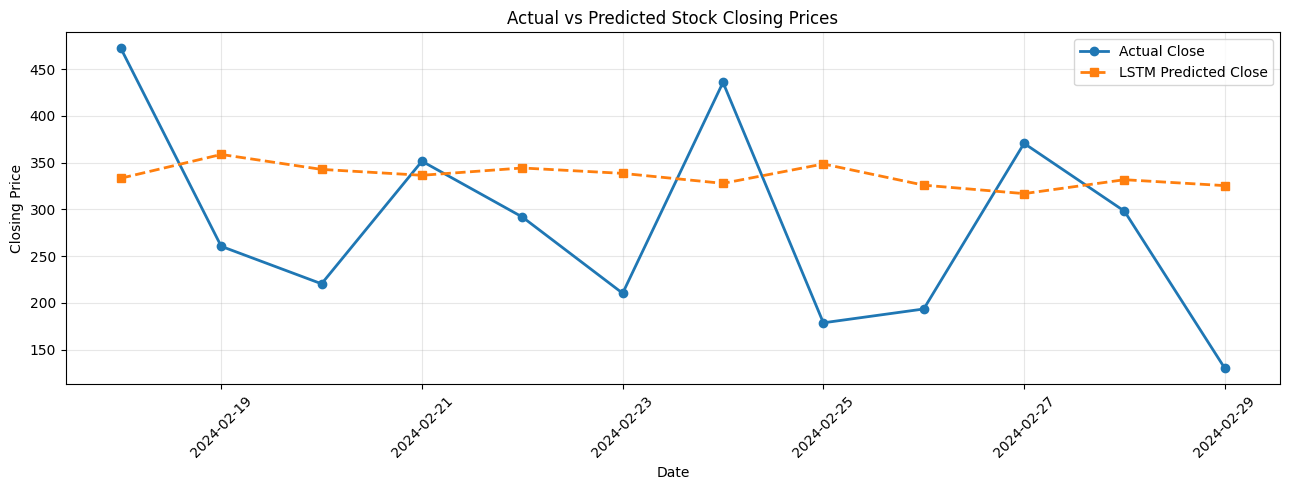

In [13]:
plt.figure(figsize=(13, 5))

plt.plot(
    test_dates,
    y_actual,
    marker="o",
    label="Actual Close",
    linewidth=2
)

plt.plot(
    test_dates,
    y_pred,
    marker="s",
    linestyle="--",
    label="LSTM Predicted Close",
    linewidth=2
)

plt.title("Actual vs Predicted Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
last_10_days = df[FEATURES].tail(LOOKBACK)

last_10_scaled = feature_scaler.transform(
    last_10_days
)

next_sequence = last_10_scaled.reshape(
    1, LOOKBACK, len(FEATURES)
).astype(np.float32)

next_close_scaled = model.predict(
    next_sequence,
    verbose=0
)

next_close = target_scaler.inverse_transform(
    next_close_scaled
)[0, 0]

last_date = df["Date"].iloc[-1]
forecast_date = last_date + pd.Timedelta(days=1)

print("Last available date:", last_date.strftime("%d/%m/%Y"))
print("Last actual closing price:", round(df["Close"].iloc[-1], 2))
print("Forecast date:", forecast_date.strftime("%d/%m/%Y"))
print("Predicted next closing price:", round(float(next_close), 2))

Last available date: 29/02/2024
Last actual closing price: 129.95
Forecast date: 01/03/2024
Predicted next closing price: 307.72


In [15]:
import joblib

model.save("stock_lstm_model.keras")

joblib.dump(
    feature_scaler,
    "feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    "target_scaler.pkl"
)

files.download("stock_lstm_model.keras")
files.download("feature_scaler.pkl")
files.download("target_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>